# 04 · Text recognition: CRNN and TrOCR

Two local models read one line image at a time. Both are trained on the **same split**, so
their numbers are directly comparable:

* **Training data**: the 3,807-line corpus from HuggingFace (`Sarthak004/renaissanceocr-spanish-printed`).
* **Split by book**: 23 books train, 3 books validate. Validation measures typefaces and paper
  the model has never seen; a random line split would leak each book into training.
* **Metrics**: character and word error rate (CER, WER) on the 851 validation lines, and on
  28 full pages from unseen books (detection + recognition together).

In [1]:
# Make experimentation/src importable (this also puts backend/ on sys.path, so the
# notebooks run the app's own preprocessing, detection and recognition code).
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
%matplotlib inline

In [2]:
import pandas as pd
from src import figures
from src.corpus import LineCorpus
from src.paths import CHECKPOINTS

train, val = LineCorpus().split()
print(f"train: {len(train)} lines from {train.book.nunique()} books | val: {len(val)} lines from {val.book.nunique()} books")
print("validation books:", sorted(val.book.unique()))
pd.DataFrame({"train": train.font.value_counts(), "val": val.font.value_counts()}).fillna(0).astype(int)

train: 2956 lines from 23 books | val: 851 lines from 3 books
validation books: ['Buendia - Instruccion', 'PADILLA 1 Nobleza Virtuosa 1637', 'PORCONES.200.2 ÔÇô 1670']


,train,val
font,,
roman,1662,623
gothic,1227,218
italic,37,6
uppercase,18,3
mixed,12,1


## CRNN: CNN + BiLSTM + CTC

![CRNN](../../assets/06_crnn_architecture.png)

A small ResNet turns the line into a left-to-right sequence of W/4 feature columns, a 3-layer
BiLSTM adds context from both sides, and every column predicts a character or a *blank*.
**CTC loss** sums over every alignment of columns to characters, so training needs only the
line's text, not where each character is. Trained from scratch; the architecture is imported
from the app (`crnn_inference.CRNN`), so the trained checkpoint is exactly what the app serves.

Fixes in this training run: one output class per character **plus the blank** (the first run
had one class too few), batches padded with **white** instead of black and each line's true
width passed to CTC, the vocabulary built from training books only, and one corrupt sample
(a whole text block labelled as one line) dropped.

In [3]:
from src.crnn import CRNN, Charset

charset = Charset.from_texts(train.text)
model = CRNN(charset.num_classes, lstm_hidden=256, lstm_layers=3)
print(f"{len(charset.chars)} characters + blank = {charset.num_classes} classes | "
      f"{sum(p.numel() for p in model.parameters()) / 1e6:.1f} M parameters")

93 characters + blank = 94 classes | 8.2 M parameters


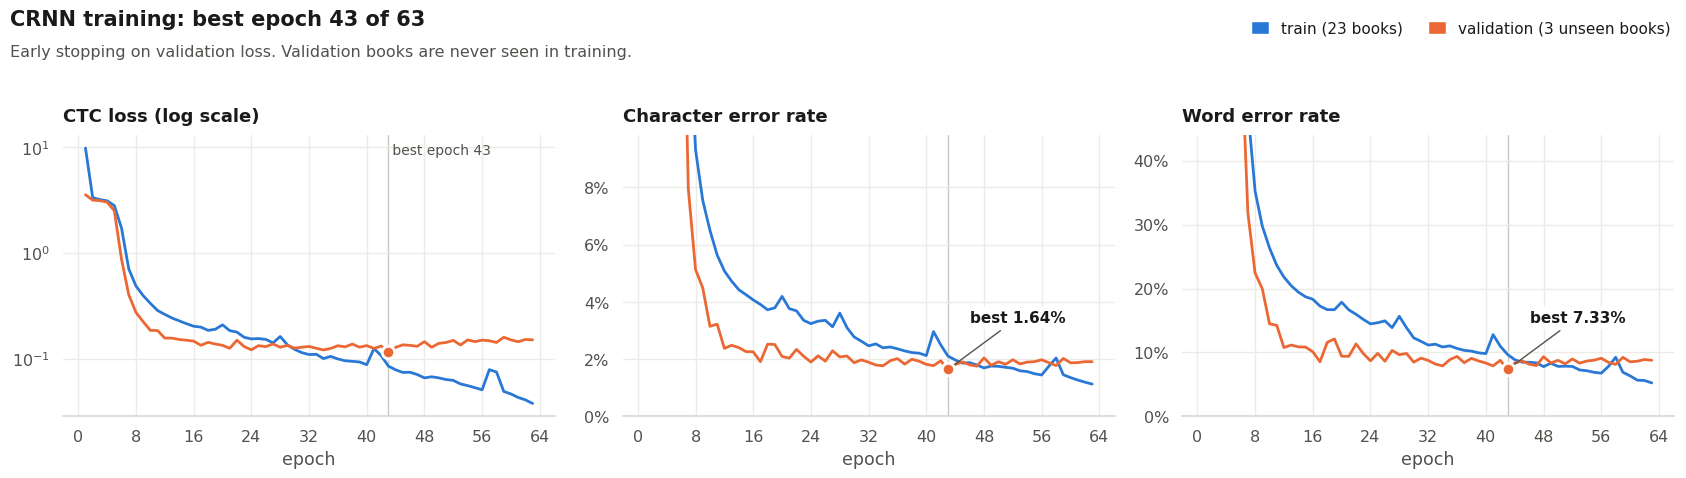

In [4]:
if not (CHECKPOINTS / "crnn" / "best_crnn.pth").exists():
    !python ../scripts/train.py crnn   # ~1.5 h on an RTX 4060, in its own process
figures.training_curves("CRNN");

## TrOCR: Vision Transformer encoder + Transformer decoder

Fine-tuned from `microsoft/trocr-base-printed` (334 M parameters). The encoder cuts the line,
resized to 384×384, into 576 patches; the decoder writes BPE tokens one at a time, attending
to the patches (cross-attention). Trained with cross-entropy and teacher forcing.

The first fine-tune was unstable (training loss rose after epoch 2). This run fixes it:
the pretrained start token is kept (the first run overrode it), the duplicated `<s>` label is
dropped, the learning rate is lower (2e-5, warm-up + cosine), the effective batch is larger
(16) and it trains in bf16.

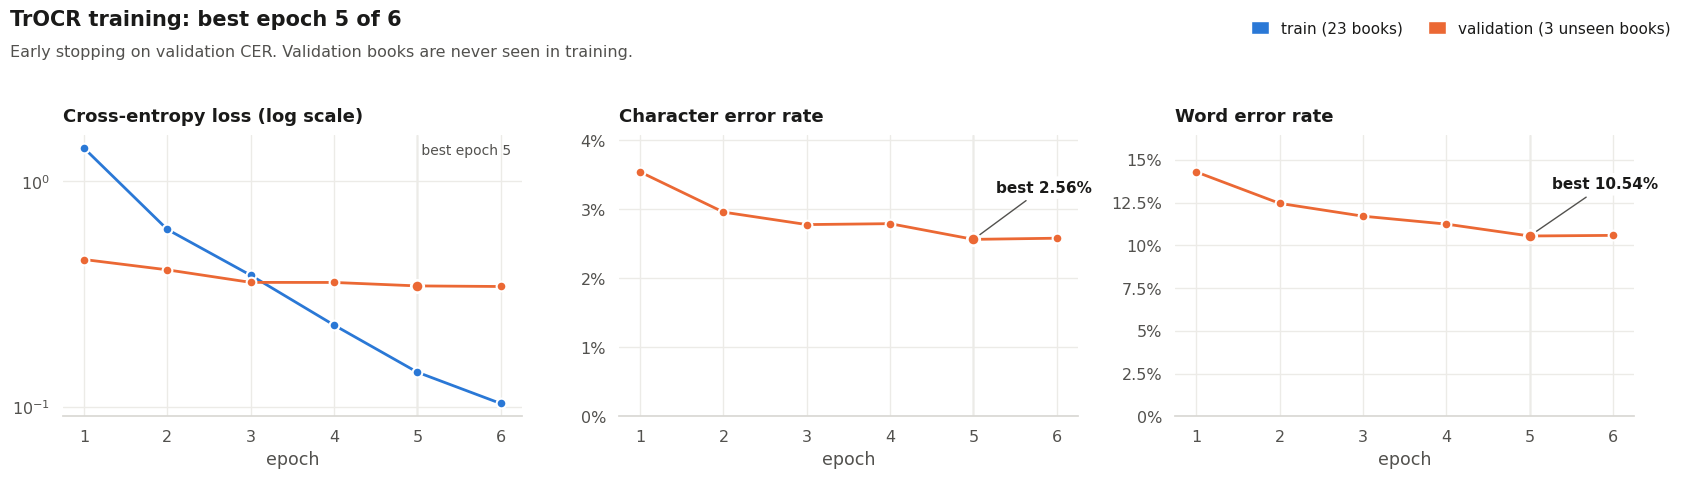

In [5]:
if not (CHECKPOINTS / "trocr" / "model.safetensors").exists():
    !python ../scripts/train.py trocr   # ~20 min on an RTX 4060, in its own process
figures.training_curves("TrOCR");

## Results

Produced by `scripts/evaluate.py` (detect → recognize → report), each step in its own process.
*Previous* models are the ones the app shipped before this retraining. The previous TrOCR was
trained on a random line split, so it saw most validation lines and books: its line-level
numbers here are not a fair test.

In [6]:
res = figures.results()
def row(name):
    r = res[name]
    return {"line CER": r["line"]["cer"], "line WER": r["line"]["wer"],
            "page CER (raw scan)": r["page_raw"]["cer"], "page WER (raw scan)": r["page_raw"]["wer"],
            "page CER (preprocessed)": r["page_cleaned"]["cer"], "page WER (preprocessed)": r["page_cleaned"]["wer"]}
table = pd.DataFrame({n: row(n) for n in ("CRNN", "TrOCR", "CRNN previous", "TrOCR previous") if n in res}).T
table.style.format("{:.2%}")

,line CER,line WER,page CER (raw scan),page WER (raw scan),page CER (preprocessed),page WER (preprocessed)
CRNN,1.64%,7.31%,5.90%,21.67%,14.17%,35.91%
TrOCR,2.57%,10.54%,6.08%,21.34%,11.82%,27.58%
CRNN previous,1.79%,7.92%,6.05%,21.70%,13.71%,34.33%
TrOCR previous,1.70%,6.60%,6.67%,22.22%,12.25%,28.95%


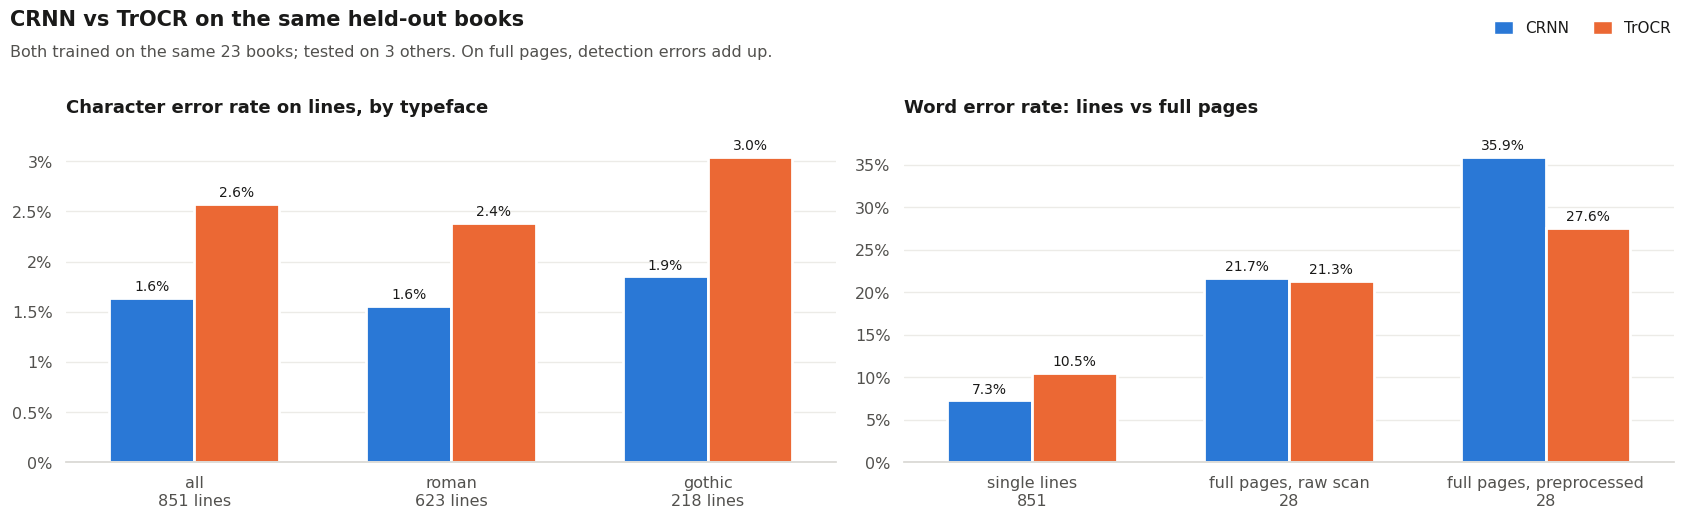

In [7]:
figures.recognition_comparison();

### Why page-level error is higher: detection

For every true line of a page we look for the recognized line that matches it best. A true
line without any reasonable match was lost or mangled by detection (missed box, box cutting
through a decoration). The CER on the lines that *were* found isolates recognition.

In [8]:
rows = {}
for n in ("CRNN", "TrOCR"):
    for p in ("raw", "cleaned"):
        found = res[n][f"page_{p}_found_lines"]
        rows[f"{n}, {p} scan"] = {"page CER": f'{res[n][f"page_{p}"]["cer"]:.2%}',
                                  "CER on found lines": f'{found["cer"]:.2%}',
                                  "lines lost": f'{found["lost"]} / {found["total"]}'}
pd.DataFrame(rows).T

,page CER,CER on found lines,lines lost
"CRNN, raw scan",5.90%,4.07%,17 / 588
"CRNN, cleaned scan",14.17%,8.00%,58 / 588
"TrOCR, raw scan",6.08%,4.38%,16 / 588
"TrOCR, cleaned scan",11.82%,5.66%,55 / 588


In [9]:
pd.DataFrame({f"{n} {level}": {book: f'{v["cer"]:.1%} / {v["wer"]:.1%}' for book, v in res[n][key].items()}
              for n in ("CRNN", "TrOCR") for level, key in (("lines", "line_by_book"), ("pages", "page_cleaned_by_book"))})

,CRNN lines,CRNN pages,TrOCR lines,TrOCR pages
Buendia - Instruccion,2.9% / 10.3%,8.6% / 20.2%,3.2% / 11.2%,7.2% / 15.9%
PADILLA 1 Nobleza Virtuosa 1637,1.3% / 5.8%,NaN,2.0% / 8.7%,NaN
PORCONES.200.2 ÔÇô 1670,2.2% / 10.7%,NaN,3.9% / 15.6%,NaN
PORCONES.23.5 - 1628,NaN,7.8% / 27.9%,NaN,6.7% / 22.0%
Padilla - Nobleza virtuosa,NaN,21.5% / 48.4%,NaN,17.8% / 36.5%


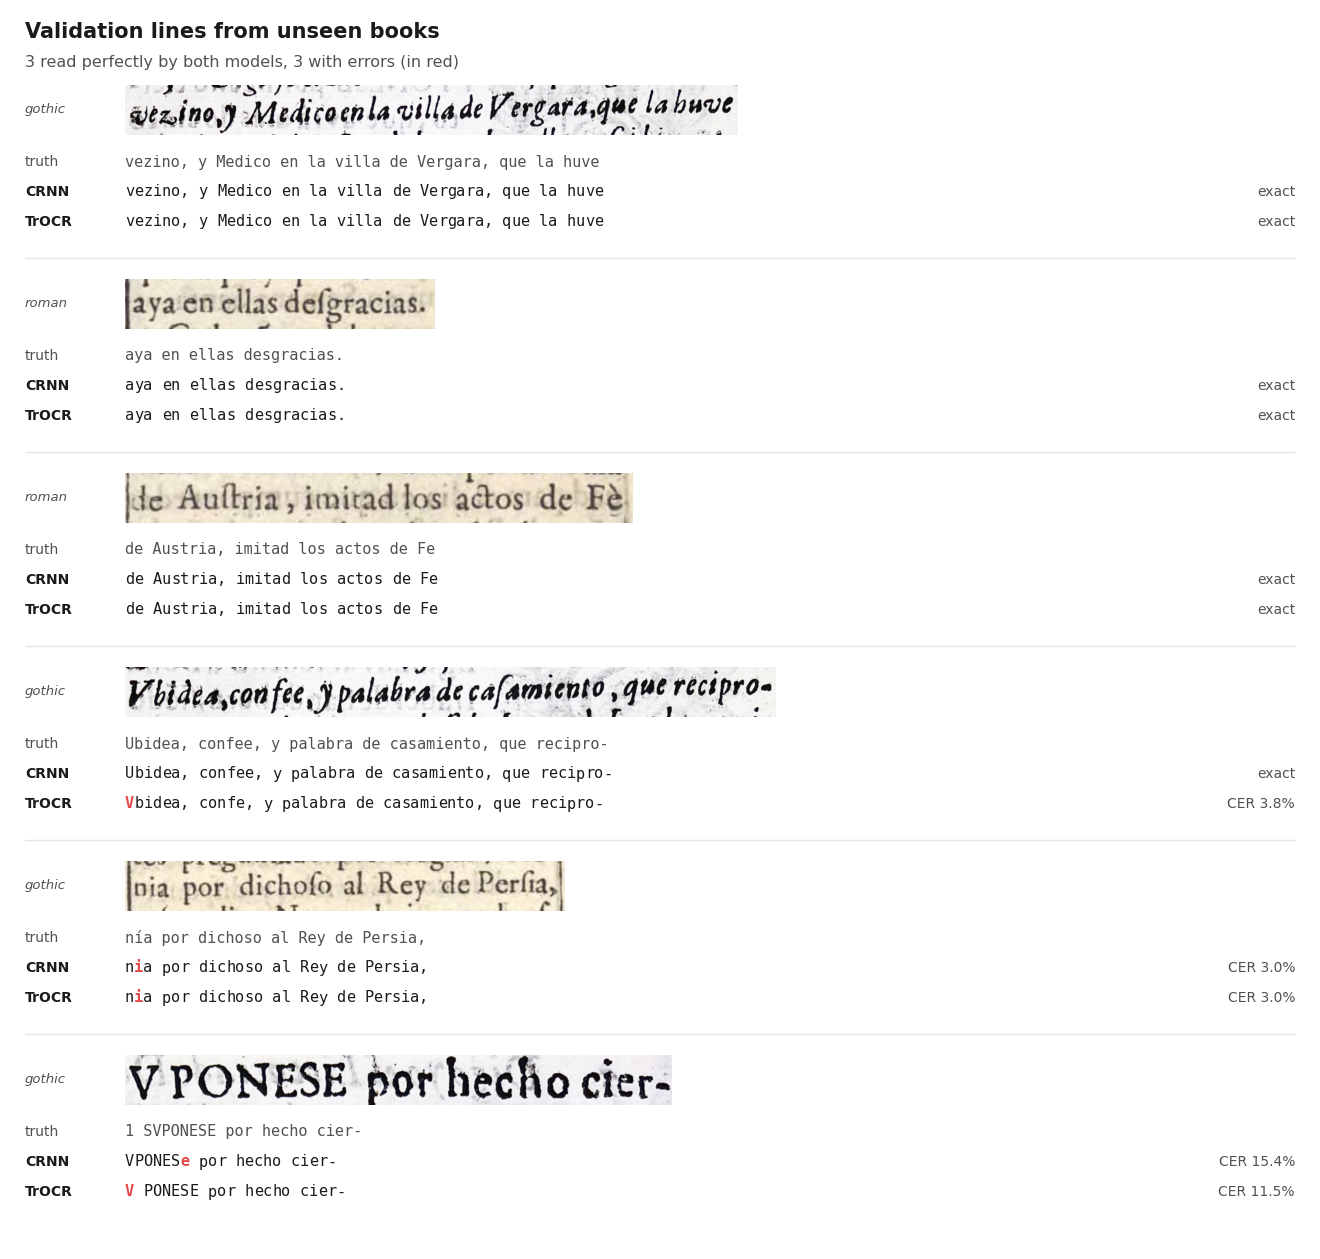

In [10]:
figures.recognition_samples();

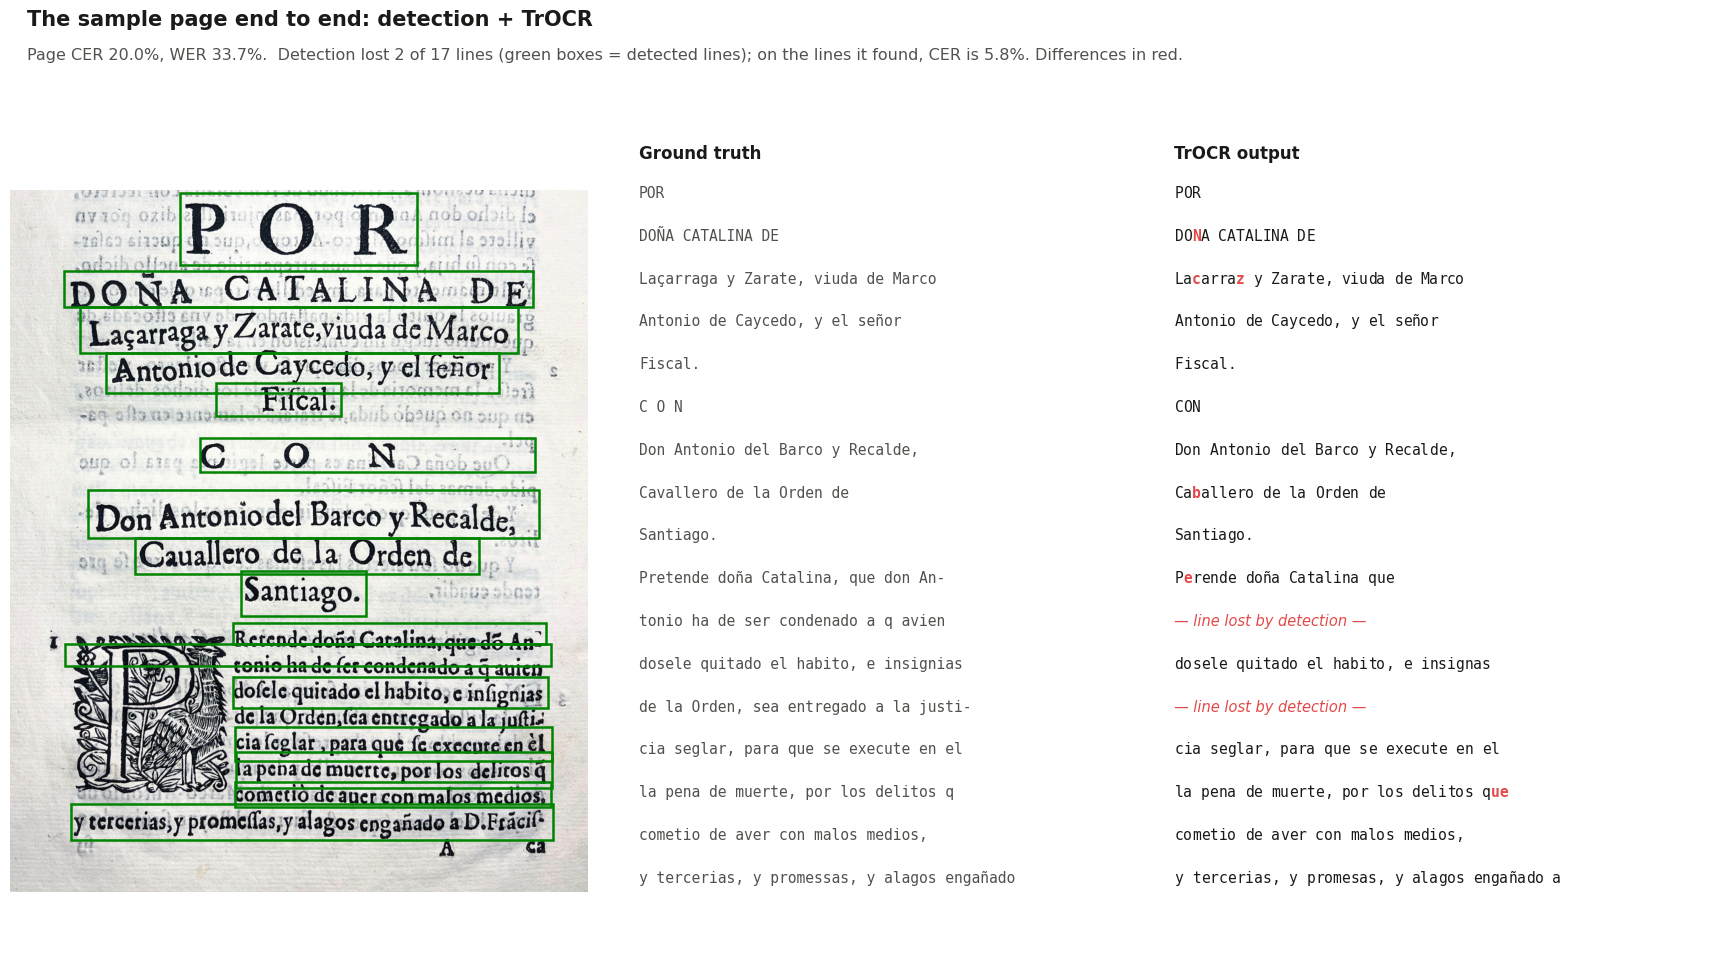

In [11]:
figures.sample_page();

## TrOCR quantization

The same checkpoint loaded at lower precision (bitsandbytes post-training quantization).
The app serves the fp16 model on GPUs.

In [12]:
from src.trocr import benchmark_precisions

csv = CHECKPOINTS / "trocr" / "quantization.csv"
if not csv.exists():
    benchmark_precisions(CHECKPOINTS / "trocr", val).to_csv(csv)
pd.read_csv(csv, index_col=0).style.format({"cer": "{:.2%}", "wer": "{:.2%}", "size_mb": "{:.0f}", "ms_per_line": "{:.0f}"})

,cer,wer,size_mb,ms_per_line
precision,,,,
fp32,2.57%,10.52%,1274,103
fp16,2.58%,10.52%,637,34
int8,2.60%,10.65%,471,144
4-bit NF4,2.92%,11.72%,337,68
4-bit FP4,3.14%,13.22%,337,67


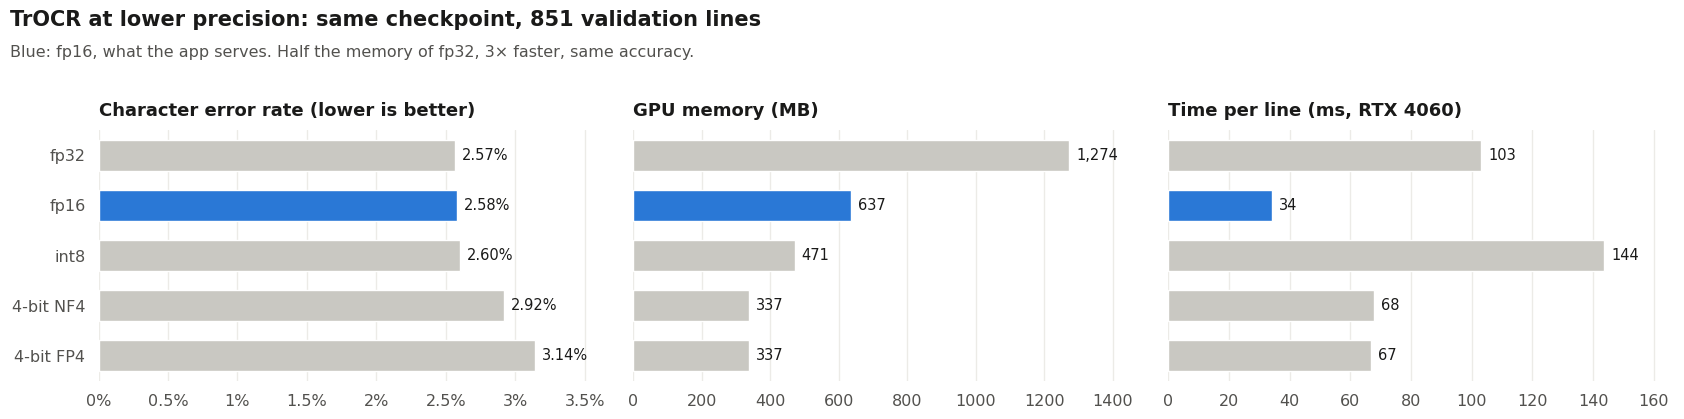

In [13]:
figures.quantization_tradeoff();